# Evaluation

This notebook performs the final held-out evaluation of the model selected in modelling.ipynb.

Evaluation contract:

- Load the fitted model and chosen hyperparameters saved by the modelling notebook.
- Recreate the same personalized dataset, seed, target mapping, excluded feature, and stratified 80/20 split.
- Verify the dataset fingerprint before evaluation.
- Score the held-out test set once with the frozen model.
- Do not select hyperparameters or decision thresholds using test results.

In [1]:
# Import the libraries needed for model evaluation.
from pathlib import Path
import hashlib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

# Set a consistent style for the plots.
sns.set_theme(style="whitegrid")


# Apply the same feature engineering used in the modelling notebook.
def engineer_features(data):
    data = data.copy()

    days = data["pdays"].replace(-1, 0)

    data["previously_contacted"] = (data["pdays"] != -1).astype(int)
    data["campaign_log1p"] = np.log1p(data["campaign"])
    data["previous_log1p"] = np.log1p(data["previous"])
    data["days_since_previous_contact_log1p"] = np.log1p(days)

    return data.drop(columns=["pdays", "campaign", "previous"])


# Define the paths to the dataset and saved model.
PROJECT_DIR = Path("..")
DATA_PATH = PROJECT_DIR / "data" / "bank_personalized.csv"
MODEL_PATH = PROJECT_DIR / "artifacts" / "best_model.joblib"
METADATA_PATH = PROJECT_DIR / "artifacts" / "best_model_metadata.json"

In [2]:
# Load the saved model, metadata, and dataset.
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
best_model = joblib.load(MODEL_PATH)
df = pd.read_csv(DATA_PATH)

# Check that the dataset matches the one used during training.
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == metadata["data_sha256"]
assert metadata["excluded_features"] == ["duration"]
assert set(df["y"].dropna().unique()) == {"no", "yes"}

# Get the original training settings and selected threshold.
RANDOM_STATE = metadata["random_state"]
TEST_SIZE = metadata.get("test_size", 0.20)
best_threshold = float(metadata.get("selected_threshold", metadata.get("threshold")))

# Separate features and target, excluding duration.
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})
assert y.notna().all()

# Recreate the original 80/20 stratified train-test split.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Selected model:", metadata.get("selected_model_family", metadata.get("model")))
print("Selected threshold:", best_threshold)
print("Primary metric:", metadata["primary_metric"])
print("Test dataset shape:", X_test.shape)
print("Test target distribution (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Selected model: Gradient boosting
Selected threshold: 0.65
Primary metric: f1
Test dataset shape: (7234, 15)
Test target distribution (%):
y
0    88.31
1    11.69
Name: proportion, dtype: float64


In [3]:
# Evaluate the selected model on the held-out test dataset.

# Predict subscription probabilities and apply the selected threshold.
y_test_probability = best_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_probability >= best_threshold).astype(int)

# Calculate the evaluation metrics.
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_test_probability),
    "Average precision": average_precision_score(y_test, y_test_probability),
}, name="Test score")

# Calculate baseline scores for comparison.
baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())
positive_prevalence = y_test.mean()

# Display the model's results and baseline scores.
display(test_metrics.to_frame().round(4))

print("Majority-class accuracy baseline:", round(baseline_accuracy, 4))
print("Positive-class prevalence:", round(positive_prevalence, 4))

,Test score
Accuracy,0.8703
Balanced accuracy,0.7112
Precision,0.4513
Recall,0.5035
F1-score,0.4760
ROC AUC,0.8072
Average precision,0.4443


Majority-class accuracy baseline: 0.8831
Positive-class prevalence: 0.1169


In [4]:
# Display precision, recall, F1 score, and support for each class.
report = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["No subscription", "Subscription"],
        output_dict=True,
        zero_division=0,
    )
).T

display(report.round(4))

,precision,recall,f1-score,support
No subscription,0.9332,0.9189,0.9260,6388.0000
Subscription,0.4513,0.5035,0.4760,846.0000
accuracy,0.8703,0.8703,0.8703,0.8703
macro avg,0.6922,0.7112,0.7010,7234.0000
weighted avg,0.8769,0.8703,0.8734,7234.0000


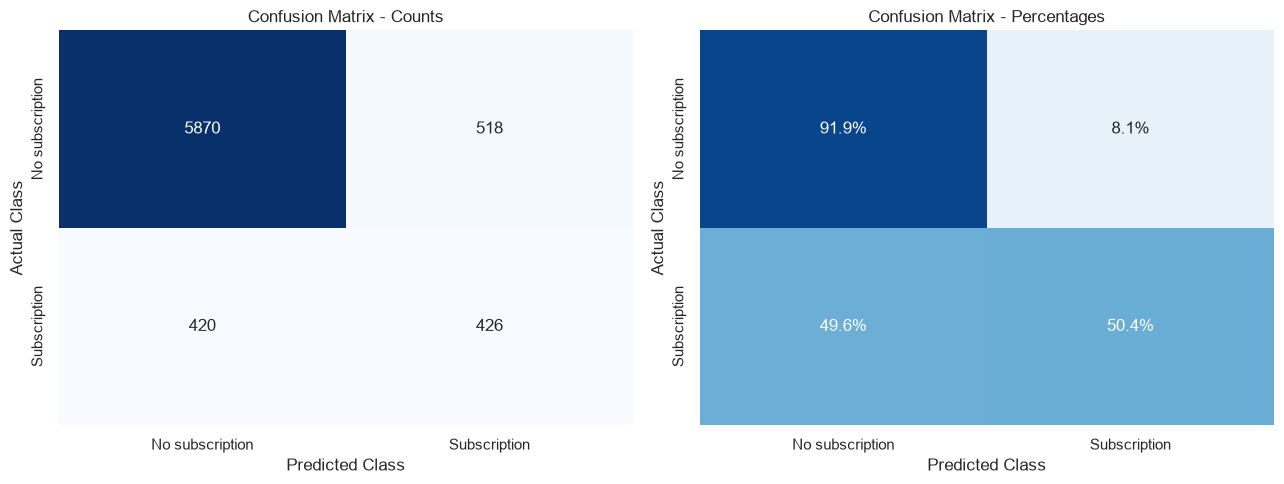

In [5]:
# Display confusion matrices to evaluate correct and incorrect predictions.

# Calculate the confusion matrix using counts and percentages.
class_names = ["No subscription", "Subscription"]

cm = confusion_matrix(y_test, y_test_pred)
cm_percent = confusion_matrix(y_test, y_test_pred, normalize="true")

# Create two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot the number of correct and incorrect predictions.
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=class_names, yticklabels=class_names, ax=axes[0]
)
axes[0].set(
    title="Confusion Matrix - Counts",
    xlabel="Predicted Class",
    ylabel="Actual Class"
)

# Plot the percentage of predictions within each actual class.
sns.heatmap(
    cm_percent, annot=True, fmt=".1%", cmap="Blues", cbar=False,
    vmin=0, vmax=1,
    xticklabels=class_names, yticklabels=class_names, ax=axes[1]
)
axes[1].set(
    title="Confusion Matrix - Percentages",
    xlabel="Predicted Class",
    ylabel="Actual Class"
)

plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

- **True Negatives (5,870):** The model correctly identified 91.9% of customers who did not subscribe.
- **True Positives (426):** The model correctly identified 50.4% of customers who subscribed.
- **False Positives (518):** The model incorrectly predicted that 518 customers would subscribe when they did not.
- **False Negatives (420):** The model failed to identify 420 customers who actually subscribed.
- **Overall:** The model performs well at identifying non-subscribers but struggles to identify all potential subscribers. Its recall of 50.4% indicates that nearly half of actual subscribers are missed, while the false positives suggest unnecessary marketing efforts.

**Conclusion:** The model is more effective at identifying non-subscribers than subscribers, highlighting the difficulty of predicting the minority class in an imbalanced dataset.

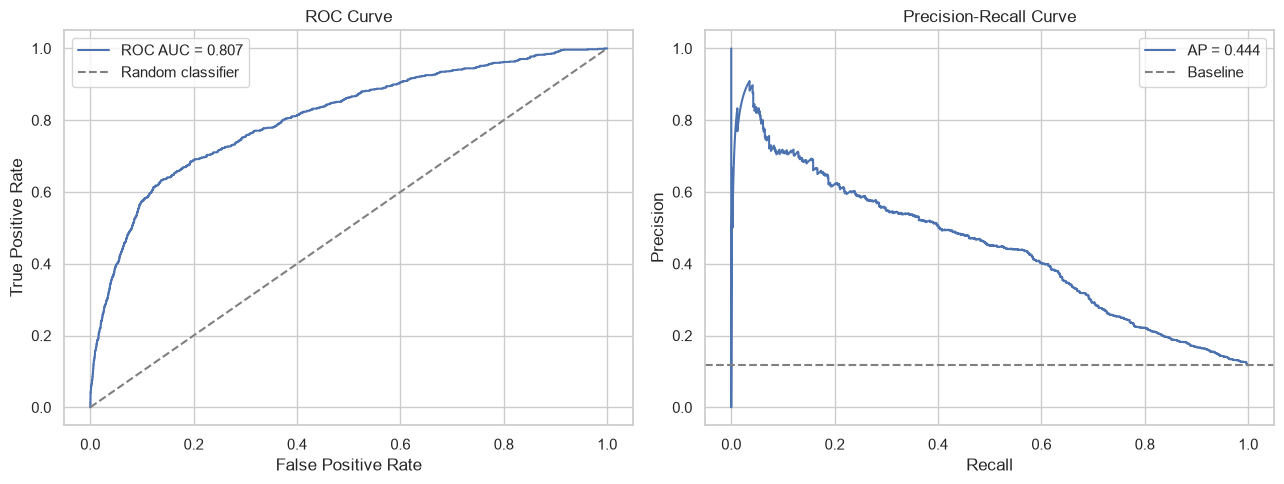

In [6]:
# Plot the ROC and Precision-Recall curves to evaluate the model across different thresholds.

# Calculate the points for both curves.
fpr, tpr, _ = roc_curve(y_test, y_test_probability)
precision, recall, _ = precision_recall_curve(y_test, y_test_probability)

# Create two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot the ROC curve and compare it with random classification.
axes[0].plot(fpr, tpr, label=f"ROC AUC = {test_metrics['ROC AUC']:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random classifier")
axes[0].set(
    title="ROC Curve",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)
axes[0].legend()

# Plot the Precision-Recall curve and compare it with the subscription rate.
axes[1].plot(recall, precision, label=f"AP = {test_metrics['Average precision']:.3f}")
axes[1].axhline(positive_prevalence, linestyle="--", color="gray", label="Baseline")
axes[1].set(
    title="Precision-Recall Curve",
    xlabel="Recall",
    ylabel="Precision"
)
axes[1].legend()

plt.tight_layout()
plt.show()

### ROC and Precision-Recall Curve Analysis

- **ROC AUC (0.807):** The model demonstrates good ability to distinguish between customers who subscribe and those who do not.
- **ROC Curve:** The curve remains well above the random classifier baseline, indicating better-than-random classification performance.
- **Average Precision (0.444):** The model shows moderate precision-recall performance when identifying potential subscribers.
- **Precision-Recall Curve:** Precision generally decreases as recall increases, showing the trade-off between identifying more subscribers and making more false positive predictions.
- **Class Imbalance:** The Precision-Recall curve remains above the baseline subscription rate (approximately 11.7%) for most recall values, indicating that the model performs considerably better than random ranking.

**Overall:** The model demonstrates good class discrimination, but identifying subscribers accurately remains challenging. Its performance is meaningful given the imbalanced dataset, although there is still room for improvement.

In [7]:

# Analyze the model's prediction errors across different customer groups.

# Create a table containing actual and predicted results.
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = y_test_pred

# Classify predictions as correct, false positive, or false negative.
errors["error_type"] = np.select(
    [
        (errors["actual"] == 1) & (errors["predicted"] == 0),
        (errors["actual"] == 0) & (errors["predicted"] == 1)
    ],
    ["False negative", "False positive"],
    default="Correct"
)

# Display the total number of each prediction type.
display(errors["error_type"].value_counts())

# Compare error percentages across contact methods, previous outcomes, and months.
for feature in ["contact", "poutcome", "month"]:
    summary = pd.crosstab(
        errors[feature],
        errors["error_type"],
        normalize="index"
    ) * 100

    print(f"\nError distribution by {feature} (%)")
    display(summary.round(2))


error_type
Correct           6296
False positive     518
False negative     420
Name: count, dtype: int64


Error distribution by contact (%)


error_type,Correct,False negative,False positive
contact,,,
cellular,83.44,7.00,9.56
telephone,81.19,5.32,13.50
unknown,96.68,3.18,0.15



Error distribution by poutcome (%)


error_type,Correct,False negative,False positive
poutcome,,,
failure,81.16,6.20,12.64
other,77.48,6.29,16.23
success,63.10,0.00,36.90
unknown,89.36,5.98,4.67



Error distribution by month (%)


error_type,Correct,False negative,False positive
month,,,
apr,77.89,6.07,16.05
aug,87.20,7.09,5.71
dec,51.61,6.45,41.94
feb,81.32,7.25,11.43
jan,89.32,5.56,5.13
jul,90.96,7.03,2.01
jun,87.98,4.09,7.93
mar,46.97,0.00,53.03
may,92.93,4.48,2.59


### Error Analysis

- **Overall Performance:** The model correctly classified 6,296 customers, with 518 false positives and 420 false negatives.
- **Contact Method:** Unknown contact methods had the highest accuracy (96.68%), while telephone contacts had the highest false positive rate (13.50% of that group).
- **Previous Campaign Outcome:** Customers with a previously successful campaign had the lowest overall accuracy (63.10%) and a relatively high false positive percentage (36.90%). This suggests the model may overestimate subscription likelihood for these customers.
- **Month:** Prediction errors varied considerably across months. March (53.03%), October (47.58%), and December (41.94%) showed particularly high false positive percentages, while May (92.93%) and July (90.96%) had the highest overall accuracy.
- **False Negatives:** The model missed 420 actual subscribers, indicating that identifying potential subscribers remains a challenge.

**Overall:** Model performance varies across contact methods, previous campaign outcomes, and months. However, these differences may partly reflect variations in subscription rates and group sizes, rather than weaknesses in the model itself. Further analysis would be needed before drawing stronger conclusions.

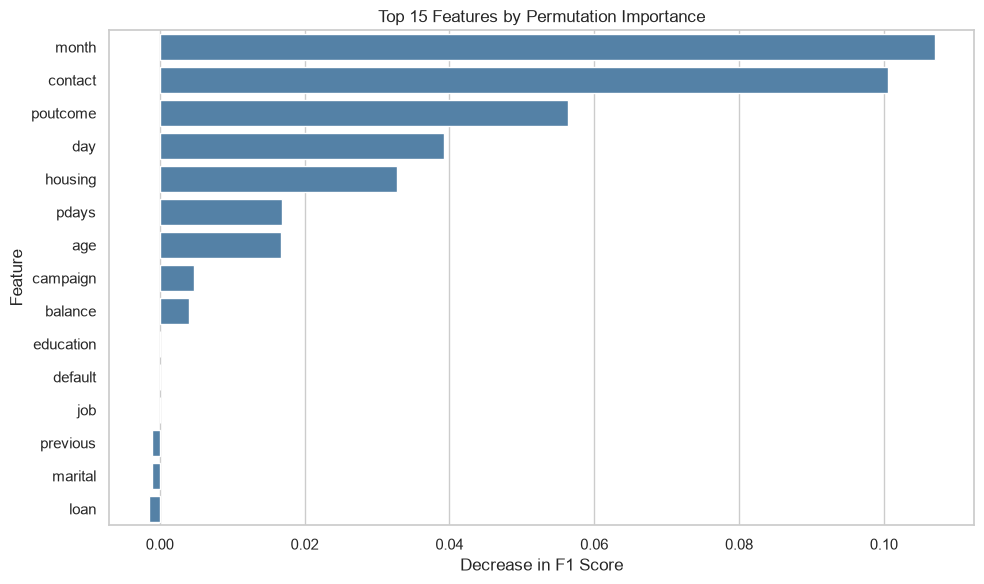

,feature,importance
10,month,0.1070
8,contact,0.1006
14,poutcome,0.0564
9,day,0.0392
6,housing,0.0328
12,pdays,0.0168
0,age,0.0168
11,campaign,0.0048
5,balance,0.0040
3,education,0.0001


In [8]:

# Identify the most important features using permutation importance.

# Measure how much shuffling each feature reduces the model's F1 score.
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
   scoring=lambda model, X, y: f1_score(
        y,
        (model.predict_proba(X)[:, 1] >= best_threshold).astype(int),
        zero_division=0
    ),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Create a table containing each feature's importance.
importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance": importance.importances_mean,
})

# Select the 15 most important features.
top_features = importance_table.nlargest(15, "importance")

# Plot the results.
plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x="importance", y="feature", color="steelblue")

plt.title("Top 15 Features by Permutation Importance")
plt.xlabel("Decrease in F1 Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(top_features.round(4))

### Feature Importance Analysis

- **Most Important Features:** `month` (0.1070), `contact` (0.1006), and `poutcome` (0.0564) had the highest permutation importance, indicating that campaign timing, contact method, and previous campaign outcomes contribute most strongly to the model's F1 score.
- **Customer Characteristics:** `housing` (0.0328) and `age` (0.0168) showed moderate importance, while `balance` (0.0040) had a smaller contribution.
- **Previous Campaign History:** `poutcome` (0.0564) and `pdays` (0.0168) suggest that previous marketing interactions provide useful predictive information.
- **Less Important Features:** `job`, `education`, `marital`, `default`, `previous`, and `loan` showed little or no positive importance, suggesting limited individual contributions to the model's F1 score.

**Overall:** Campaign timing, contact method, and previous campaign outcomes were the most influential features in this analysis. However, permutation importance measures the decrease in F1 when a feature is shuffled, not its direct effect on subscription probability. Correlations between features may also affect their importance scores.